In [1]:
import autograd.numpy as anp
import pymanopt
from pymanopt.manifolds import Sphere, Product
import numpy as np
from pymanopt.tools import diagnostics
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from autograd import value_and_grad

In [2]:
n = 2
manifold_1 = Sphere(n)
manifold_2 = Sphere(n)
manifold = Product([manifold_1, manifold_2])

In [3]:
@pymanopt.function.autograd(manifold)
def cost(point):
    return anp.sin(point[0]) + anp.sin(point[1])

In [4]:
x = np.linspace(0, 2*np.pi, 100)
y = np.linspace(0, 2*np.pi, 100)
X, Y = np.meshgrid(x, y)
Z = cost([X,Y])

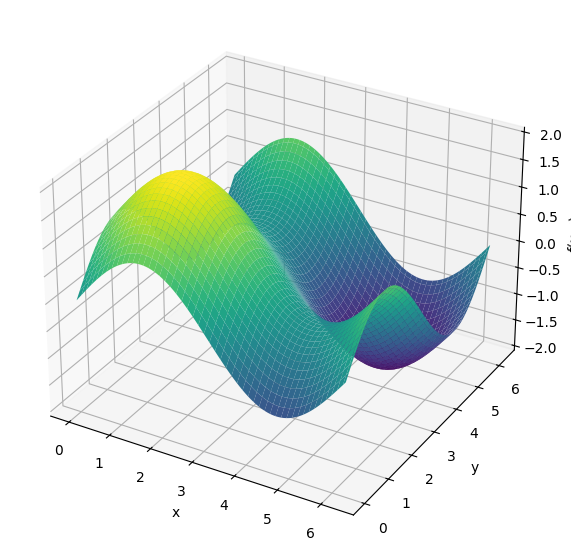

In [5]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X, Y, Z, cmap='viridis')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f(x,y)')
plt.show()

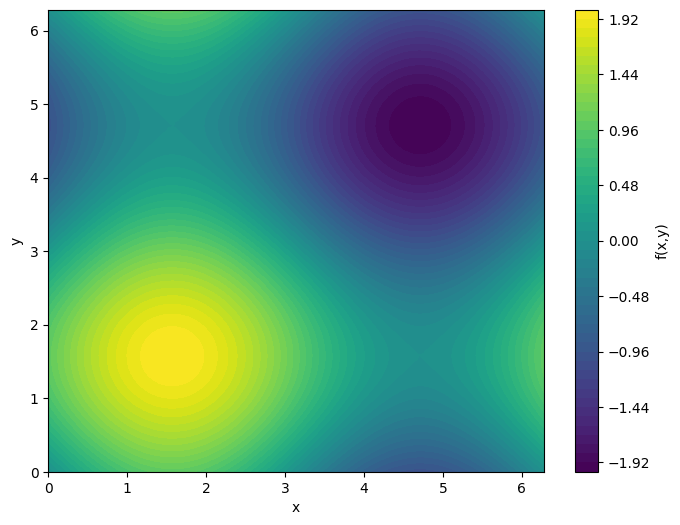

In [6]:
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(label='f(x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [9]:
n_starts = 15
fun_jac = value_and_grad(cost)
result = []
histories = []
bounds = [(0, 2*np.pi)]*2
for i in range(n_starts):
    history = []
    x0 = np.random.uniform(0.2, 2*np.pi - 0.2, size=2)
    # x0 = anp.array([0, 4*np.pi / 3])
    def callback(xk):
        f_val, grad = fun_jac(xk)
        history.append({
            "x": xk.copy(),
            "f": f_val,
            "grad_norm": np.linalg.norm(grad)
        })
    r = minimize(fun_jac, x0, jac=True, bounds=bounds, method="L-BFGS-B", callback=callback)
    histories.append(history)
    print(f"Run {i}: optimal point: {r.x} | minimum value: {r.fun}")

Run 0: optimal point: [4.71238872 4.71238937] | minimum value: -1.9999999999998883
Run 1: optimal point: [4.71238898 4.71238744] | minimum value: -1.9999999999988196
Run 2: optimal point: [0.         4.71238898] | minimum value: -1.0
Run 3: optimal point: [4.71238898 0.        ] | minimum value: -1.0
Run 4: optimal point: [4.71238898 0.        ] | minimum value: -1.0
Run 5: optimal point: [4.71238907 0.        ] | minimum value: -0.9999999999999961
Run 6: optimal point: [4.71238901 4.71238888] | minimum value: -1.9999999999999944
Run 7: optimal point: [0. 0.] | minimum value: 0.0
Run 8: optimal point: [0.         4.71238948] | minimum value: -0.9999999999998773
Run 9: optimal point: [0.         4.71238898] | minimum value: -1.0
Run 10: optimal point: [4.71238338 0.        ] | minimum value: -0.9999999999843251
Run 11: optimal point: [0.       4.712389] | minimum value: -0.9999999999999999
Run 12: optimal point: [4.71238904 4.71238837] | minimum value: -1.9999999999998124
Run 13: optima

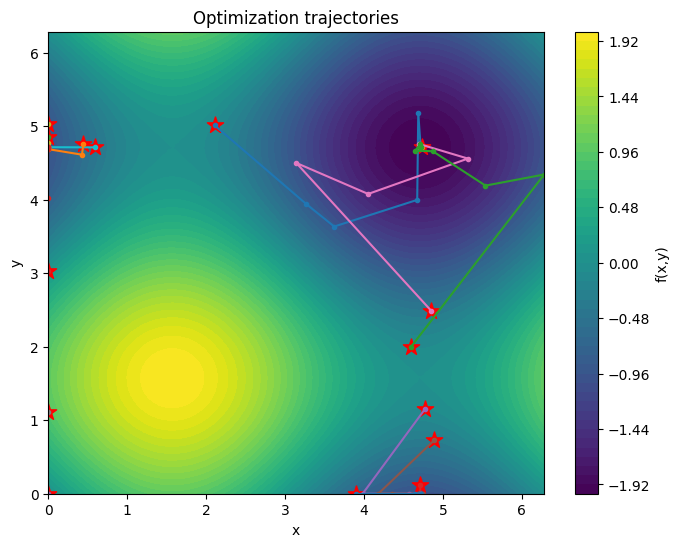

In [10]:
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(label='f(x,y)')
for i, history in enumerate(histories):
    points = np.array([h["x"] for h in history])

    # Optimization trajectory
    plt.plot(points[:, 0], points[:, 1], '-o', markersize=3)

    # Initial point
    plt.scatter(points[0, 0], points[0, 1],
                marker='*', color='red', s=150,
                label='Initial point' if i == 0 else None)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Optimization trajectories")
plt.show()

In [11]:
@pymanopt.function.autograd(manifold)
def riemannian_cost(point_1, point_2):
    return point_1[1] + point_2[1]

problem = pymanopt.Problem(manifold, riemannian_cost)

for i in range(n_starts): 
    X0 = problem.manifold.random_point()
    optimizer = pymanopt.optimizers.SteepestDescent(verbosity=0)
    result = optimizer.run(problem, initial_point=X0)
    print(f"Run {i+1}: {result.point}, {result.cost} ")

Run 1: [array([-1.32988244e-07, -1.00000000e+00]), array([-1.42283649e-07, -1.00000000e+00])], -1.9999999999999811 
Run 2: [array([-5.41935048e-09, -1.00000000e+00]), array([-1.25501292e-07, -1.00000000e+00])], -1.9999999999999922 
Run 3: [array([-4.9056405e-07, -1.0000000e+00]), array([ 5.41431606e-07, -1.00000000e+00])], -1.999999999999733 
Run 4: [array([ 9.21703026e-09, -1.00000000e+00]), array([-2.24255307e-08, -1.00000000e+00])], -1.9999999999999998 
Run 5: [array([-2.03426642e-08, -1.00000000e+00]), array([ 1.50916129e-08, -1.00000000e+00])], -1.9999999999999998 
Run 6: [array([ 1.12742873e-07, -1.00000000e+00]), array([ 1.23893697e-07, -1.00000000e+00])], -1.9999999999999862 
Run 7: [array([ 1.10709596e-08, -1.00000000e+00]), array([-4.37721606e-10, -1.00000000e+00])], -2.0 
Run 8: [array([-2.54164361e-07, -1.00000000e+00]), array([-1.97464634e-07, -1.00000000e+00])], -1.9999999999999483 
Run 9: [array([-5.31082701e-09, -1.00000000e+00]), array([-1.17707086e-12, -1.00000000e+00